# Full Study Area FVC Prediction Maps

## GEOM7001 — Multi-sensor EO Monitoring of Mine Rehabilitation

This notebook generates spatially continuous FVC prediction maps for the New Acland Mine study area using previously trained Random Forest models.

Two prediction horizons are examined:

- **1-year:** June 2023 EO observations → June 2024 FVC
- **5-year:** June 2019 EO observations → June 2024 FVC

Both models use Sentinel-2 vegetation indices (NDVI, EVI and NDRE) and Sentinel-1 SAR backscatter (VV and VH).

Unlike the spatial validation maps, which display only withheld testing blocks, these maps include all study-area pixels with valid predictor data.

The full-area maps are intended for spatial interpretation rather than independent model validation.

## 1. Setup and Data Loading

The harmonised monthly dataset and previously trained Random Forest models are loaded directly from disk.

All spatial data use the same 30 m grid in GDA2020 / MGA Zone 56 (EPSG:7856).

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Rectangle
from matplotlib.ticker import ScalarFormatter

print("Libraries loaded.")
output_dir = Path("Report_Figures")
output_dir.mkdir(exist_ok=True)

Libraries loaded.


## reusable map-formatting function

In [2]:
def add_map_elements(ax, data_source="", scale_km=1, show_source=True):
    """
    Add BOLTSS map elements to a projected map.

    Assumes map coordinates are in metres
    (EPSG:7856).
    """

    # ----------------------------
    # 1. Border
    # ----------------------------

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.2)
        spine.set_color("black")

    # ----------------------------
    # 2. North arrow
    # ----------------------------

    ax.annotate(
        "N",
        xy=(0.92, 0.96),
        xytext=(0.92, 0.82),
        xycoords="axes fraction",
        textcoords="axes fraction",
        arrowprops=dict(arrowstyle="-|>", color="black", lw=1.8),
        ha="center",
        va="center",
        fontsize=12,
        fontweight="bold",
    )

    # ----------------------------
    # 3. Scale bar
    # ----------------------------

    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()

    scale_length = scale_km * 1000

    x_start = xmin + (xmax - xmin) * 0.08
    y_start = ymin + (ymax - ymin) * 0.07

    tick_height = (ymax - ymin) * 0.012

    ax.plot(
        [x_start, x_start + scale_length],
        [y_start, y_start],
        color="black",
        linewidth=3,
        solid_capstyle="butt",
    )

    for x in [x_start, x_start + scale_length]:
        ax.plot(
            [x, x],
            [y_start - tick_height, y_start + tick_height],
            color="black",
            linewidth=1.5,
        )

    ax.text(x_start, y_start + tick_height * 2, "0", ha="center", fontsize=9)

    ax.text(
        x_start + scale_length,
        y_start + tick_height * 2,
        f"{scale_km} km",
        ha="center",
        fontsize=9,
    )

    # ----------------------------
    # 4. Coordinates
    # ----------------------------

    ax.set_xlabel("Easting (m)", fontsize=10)
    ax.set_ylabel("Northing (m)", fontsize=10)

    ax.tick_params(labelsize=9)

    ax.ticklabel_format(style="plain", useOffset=False)

    ax.set_aspect("equal")

    # ----------------------------
    # 5. Data source
    # ----------------------------

    if show_source and data_source:

        ax.text(
            0.5,
            -0.18,
            f"Source: {data_source}",
            transform=ax.transAxes,
            ha="center",
            va="top",
            fontsize=8,
            color="dimgray",
        )

In [3]:
required_files = [
    "model_data_2016_2025.nc",
    "rf_1year_sar_importance.joblib",
    "rf_5year_sar.joblib",
]

for filename in required_files:
    path = Path(filename)

    print(filename, "FOUND" if path.exists() else "NOT FOUND")

model_data_2016_2025.nc FOUND
rf_1year_sar_importance.joblib FOUND
rf_5year_sar.joblib FOUND


In [4]:
model_data = xr.open_dataset("model_data_2016_2025.nc")

rf_1yr = joblib.load("rf_1year_sar_importance.joblib")

rf_5yr = joblib.load("rf_5year_sar.joblib")

print("Dataset:")
print(model_data)

print("\n1-year model:", type(rf_1yr).__name__)
print("5-year model:", type(rf_5yr).__name__)

Dataset:
<xarray.Dataset> Size: 149MB
Dimensions:      (time: 120, y: 216, x: 180)
Coordinates:
  * time         (time) datetime64[ns] 960B 2016-01-01 2016-02-01 ... 2025-12-01
  * x            (x) float64 1kB 3.701e+05 3.701e+05 ... 3.754e+05 3.754e+05
  * y            (y) float64 2kB 6.984e+06 6.984e+06 ... 6.977e+06 6.977e+06
Data variables:
    NDVI         (time, y, x) float32 19MB ...
    EVI          (time, y, x) float32 19MB ...
    NDRE         (time, y, x) float32 19MB ...
    VV           (time, y, x) float64 37MB ...
    VH           (time, y, x) float64 37MB ...
    FVC          (time, y, x) float32 19MB ...
    spatial_ref  int32 4B ...

1-year model: RandomForestRegressor
5-year model: RandomForestRegressor


## 2. Model Compatibility Check

The predictor variables and their ordering are checked against the saved Random Forest models before generating spatial predictions.

The models are expected to use five predictors: NDVI, EVI, NDRE, VV and VH.

In [5]:
features = ["NDVI", "EVI", "NDRE", "VV", "VH"]

for name, model in [("1-year", rf_1yr), ("5-year", rf_5yr)]:

    print(f"\n{name} model")
    print("----------------")

    print("Number of predictors:", model.n_features_in_)

    if hasattr(model, "feature_names_in_"):
        print("Predictors:", list(model.feature_names_in_))
    else:
        print("Feature names not stored in model.")

    assert model.n_features_in_ == len(features)

    if hasattr(model, "feature_names_in_"):
        assert list(model.feature_names_in_) == features

print("\nModel compatibility check passed.")


1-year model
----------------
Number of predictors: 5
Predictors: ['NDVI', 'EVI', 'NDRE', 'VV', 'VH']

5-year model
----------------
Number of predictors: 5
Predictors: ['NDVI', 'EVI', 'NDRE', 'VV', 'VH']

Model compatibility check passed.


## 3. Spatial Data Availability

Predictor availability is assessed for June 2019 and June 2023, corresponding to the 5-year and 1-year prediction horizons.

Only pixels containing valid values for all five predictors are eligible for prediction.

Observed FVC for June 2024 is used as a reference for spatial comparison.

In [6]:
predictor_dates = {"1-year": "2023-06-01", "5-year": "2019-06-01"}

target_date = "2024-06-01"

for horizon, date in predictor_dates.items():

    predictors = model_data[features].sel(time=date)

    valid = predictors.to_array().notnull().all(dim="variable")

    print(f"{horizon} valid predictor pixels:", int(valid.sum()))

observed = model_data["FVC"].sel(time=target_date)

print("Valid observed FVC pixels:", int(observed.notnull().sum()))

1-year valid predictor pixels: 22952
5-year valid predictor pixels: 23436
Valid observed FVC pixels: 38880


## 4. Study Area Mask

The original study-area polygon is rasterised onto the harmonised 30 m grid.

The mask ensures that predictions are restricted to the New Acland study area rather than the surrounding rectangular raster extent.

In [7]:
import json

from affine import Affine
from rasterio.features import geometry_mask
from shapely.geometry import shape

with open("Study_site_output.json", "r") as f:
    study_json = json.load(f)

geometry = shape(study_json["features"][0]["geometry"])

x_res = float(model_data.x.values[1] - model_data.x.values[0])

y_res = float(model_data.y.values[1] - model_data.y.values[0])

transform = Affine(
    x_res,
    0,
    model_data.x.values[0] - x_res / 2,
    0,
    y_res,
    model_data.y.values[0] - y_res / 2,
)

mask_array = geometry_mask(
    [geometry],
    out_shape=(model_data.sizes["y"], model_data.sizes["x"]),
    transform=transform,
    invert=True,
)

study_mask = xr.DataArray(
    mask_array, dims=("y", "x"), coords={"y": model_data.y, "x": model_data.x}
)

print("Study area pixels:", int(study_mask.sum()))

Study area pixels: 28145


## 5. Full Study Area FVC Prediction

The previously trained Random Forest models are applied to all valid pixels within the study area.

For June 2024 FVC prediction:

- 1-year model: June 2023 predictors
- 5-year model: June 2019 predictors

Only pixels with valid values for all five predictors are used. Predictions are restricted to the study-area boundary.

In [8]:
def predict_full_area(model, predictor_date):

    # Select monthly predictors
    predictors = model_data[features].sel(time=predictor_date)

    # Identify pixels with valid predictors
    valid = predictors.to_array().notnull().all(dim="variable") & study_mask

    # Convert predictors to a DataFrame
    X = predictors.to_dataframe()[features].loc[valid.to_series()]

    # Generate predictions
    predictions = model.predict(X)

    # Create spatial prediction grid
    prediction_grid = xr.full_like(predictors["NDVI"], np.nan, dtype="float32")

    prediction_grid.values[valid.values] = predictions

    return prediction_grid

In [9]:
pred_1yr_full = predict_full_area(rf_1yr, "2023-06-01")

pred_5yr_full = predict_full_area(rf_5yr, "2019-06-01")

observed_full = model_data["FVC"].sel(time="2024-06-01").where(study_mask)

print("1-year predicted pixels:", int(pred_1yr_full.notnull().sum()))

print("5-year predicted pixels:", int(pred_5yr_full.notnull().sum()))

print("Observed FVC pixels:", int(observed_full.notnull().sum()))

1-year predicted pixels: 22952
5-year predicted pixels: 23436
Observed FVC pixels: 28145


## 6. Spatial Distribution of Predicted FVC

Full-area FVC prediction maps are generated for both prediction horizons.

Prediction errors are calculated as:

$$
Error = Predicted\ FVC - Observed\ FVC
$$

Positive errors indicate overprediction, while negative errors indicate underprediction.

These maps include all valid study-area pixels, including locations used during model training. Therefore, they are intended for spatial interpretation rather than independent accuracy assessment.

In [12]:
def plot_report_prediction(
    predicted,
    observed,
    horizon,
    predictor_year,
    target_year=2024
):

    valid = predicted.notnull() & observed.notnull()

    obs = observed.where(valid)
    pred = predicted.where(valid)

    error = pred - obs

    fig, axes = plt.subplots(
        1, 3,
        figsize=(18, 7),
        constrained_layout=True
    )

    # --------------------------------
    # Observed FVC
    # --------------------------------

    im1 = obs.plot(
        ax=axes[0],
        cmap="YlGn",
        vmin=0,
        vmax=100,
        add_colorbar=False
    )

    axes[0].set_title(
        f"(a) Observed FVC — June {target_year}",
        fontsize=12
    )

    # --------------------------------
    # Predicted FVC
    # --------------------------------

    pred.plot(
        ax=axes[1],
        cmap="YlGn",
        vmin=0,
        vmax=100,
        add_colorbar=False
    )

    axes[1].set_title(
        f"(b) Predicted FVC — {horizon}",
        fontsize=12
    )

    # --------------------------------
    # Prediction Error
    # --------------------------------

    im3 = error.plot(
        ax=axes[2],
        cmap="RdBu_r",
        norm=TwoSlopeNorm(
            vmin=-30,
            vcenter=0,
            vmax=30
        ),
        add_colorbar=False
    )

    axes[2].set_title(
        "(c) Prediction Error",
        fontsize=12
    )

    # --------------------------------
    # Map elements
    # --------------------------------

    for ax in axes:

        add_map_elements(
            ax,
            scale_km=1,
            show_source=False
        )

    # --------------------------------
    # Legends
    # --------------------------------

    cbar1 = fig.colorbar(
        im1,
        ax=axes[:2],
        shrink=0.65,
        pad=0.02
    )

    cbar1.set_label(
        "Fractional Vegetation Cover (%)"
    )

    cbar2 = fig.colorbar(
        im3,
        ax=axes[2],
        shrink=0.65,
        pad=0.02
    )

    cbar2.set_label(
        "Predicted − Observed (percentage points)"
    )

    # --------------------------------
    # Figure title
    # --------------------------------

    fig.suptitle(
        f"New Acland Mine — {horizon} FVC Prediction",
        fontsize=16,
        fontweight="bold"
    )

    # --------------------------------
    # Source information
    # --------------------------------

    fig.supxlabel(
        (
            "Sources: DEA Landsat Fractional Cover; "
            "Copernicus Sentinel-1 and Sentinel-2. "
            f"Predictors: June {predictor_year}; "
            f"Target: June {target_year}. "
            "CRS: GDA2020 / MGA Zone 56 (EPSG:7856)."
        ),
        fontsize=9
    )

    # --------------------------------
    # Export
    # --------------------------------

    filename = (
        output_dir
        / f"Report_{horizon.replace('-', '')}_FVC_Prediction.png"
    )

    plt.savefig(
        filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", filename)

    print(
        "Mean prediction error:",
        round(float(error.mean()), 2)
    )

## 7. Export Full Study Area Predictions

The observed FVC, predicted FVC and prediction errors are saved as a NetCDF dataset for subsequent spatial analysis and visualisation.

In [14]:
# Remove scalar time coordinates before merging
observed_save = observed_full.reset_coords("time", drop=True)

pred_1yr_save = pred_1yr_full.reset_coords("time", drop=True)

pred_5yr_save = pred_5yr_full.reset_coords("time", drop=True)

# Create prediction dataset
full_area_results = xr.Dataset(
    {
        "FVC_observed": observed_save,
        "FVC_predicted_1yr": pred_1yr_save,
        "FVC_predicted_5yr": pred_5yr_save,
        "Error_1yr": pred_1yr_save - observed_save,
        "Error_5yr": pred_5yr_save - observed_save,
    }
)

# Add metadata
full_area_results.attrs = {
    "title": "Full Study Area FVC Predictions",
    "study_area": "New Acland Mine, Queensland",
    "target_date": "2024-06-01",
    "prediction_horizons": "1-year and 5-year",
    "crs": "EPSG:7856",
}

# Save NetCDF
full_area_results.to_netcdf("Full_Area_FVC_Predictions_2024_06.nc")

print("Full-area prediction dataset saved.")
print(full_area_results)

Full-area prediction dataset saved.
<xarray.Dataset> Size: 781kB
Dimensions:            (x: 180, y: 216)
Coordinates:
  * x                  (x) float64 1kB 3.701e+05 3.701e+05 ... 3.754e+05
  * y                  (y) float64 2kB 6.984e+06 6.984e+06 ... 6.977e+06
Data variables:
    FVC_observed       (y, x) float32 156kB nan nan nan nan ... nan nan nan nan
    FVC_predicted_1yr  (y, x) float32 156kB nan nan nan nan ... nan nan nan nan
    FVC_predicted_5yr  (y, x) float32 156kB nan nan nan nan ... nan nan nan nan
    Error_1yr          (y, x) float32 156kB nan nan nan nan ... nan nan nan nan
    Error_5yr          (y, x) float32 156kB nan nan nan nan ... nan nan nan nan
Attributes:
    title:                Full Study Area FVC Predictions
    study_area:           New Acland Mine, Queensland
    target_date:          2024-06-01
    prediction_horizons:  1-year and 5-year
    crs:                  EPSG:7856


## 8. Spatial Comparison Between Prediction Horizons

The spatial differences between the 1-year and 5-year FVC predictions are examined for June 2024.

Both models predict FVC for the same target month, but use EO observations from different years.

The difference is calculated as:

$$
\Delta FVC = FVC_{predicted,5yr} - FVC_{predicted,1yr}
$$

Positive values indicate higher predicted FVC from the 5-year model, while negative values indicate higher predicted FVC from the 1-year model.

This comparison illustrates differences between prediction horizons rather than independently measuring prediction accuracy.

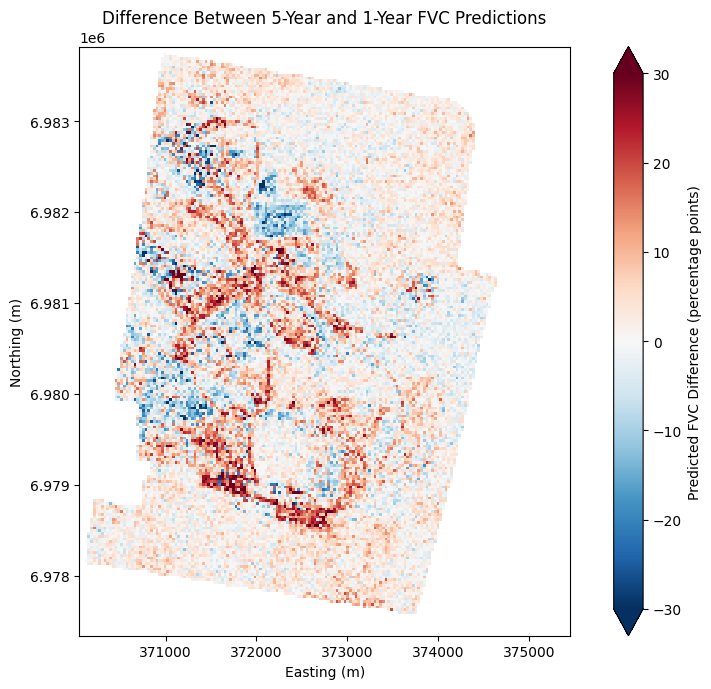

Mean prediction difference: 1.95
Valid comparison pixels: 22952


In [15]:
# Calculate prediction differences
prediction_difference = pred_5yr_full - pred_1yr_full

# Only compare pixels valid in both models
valid_comparison = pred_1yr_full.notnull() & pred_5yr_full.notnull() & study_mask

prediction_difference = prediction_difference.where(valid_comparison)

fig, ax = plt.subplots(figsize=(9, 7))

im = prediction_difference.plot(
    ax=ax,
    cmap="RdBu_r",
    vmin=-30,
    vmax=30,
    cbar_kwargs={"label": "Predicted FVC Difference (percentage points)"},
)

ax.set_title("Difference Between 5-Year and 1-Year FVC Predictions")

ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_aspect("equal")

plt.tight_layout()

plt.savefig("Prediction_Horizon_Difference.png", dpi=300, bbox_inches="tight")

plt.show()

print("Mean prediction difference:", round(float(prediction_difference.mean()), 2))

print("Valid comparison pixels:", int(valid_comparison.sum()))

In [16]:
def plot_report_prediction(
    predicted,
    observed,
    horizon,
    predictor_year,
    target_year=2024
):

    valid = predicted.notnull() & observed.notnull()

    obs = observed.where(valid)
    pred = predicted.where(valid)

    error = pred - obs

    fig, axes = plt.subplots(
        1, 3,
        figsize=(18, 7),
        constrained_layout=True
    )

    # --------------------------------
    # Observed FVC
    # --------------------------------

    im1 = obs.plot(
        ax=axes[0],
        cmap="YlGn",
        vmin=0,
        vmax=100,
        add_colorbar=False
    )

    axes[0].set_title(
        f"(a) Observed FVC — June {target_year}",
        fontsize=12
    )

    # --------------------------------
    # Predicted FVC
    # --------------------------------

    pred.plot(
        ax=axes[1],
        cmap="YlGn",
        vmin=0,
        vmax=100,
        add_colorbar=False
    )

    axes[1].set_title(
        f"(b) Predicted FVC — {horizon}",
        fontsize=12
    )

    # --------------------------------
    # Prediction Error
    # --------------------------------

    im3 = error.plot(
        ax=axes[2],
        cmap="RdBu_r",
        norm=TwoSlopeNorm(
            vmin=-30,
            vcenter=0,
            vmax=30
        ),
        add_colorbar=False
    )

    axes[2].set_title(
        "(c) Prediction Error",
        fontsize=12
    )

    # --------------------------------
    # Map elements
    # --------------------------------

    for ax in axes:

        add_map_elements(
            ax,
            scale_km=1,
            show_source=False
        )

    # --------------------------------
    # Legends
    # --------------------------------

    cbar1 = fig.colorbar(
        im1,
        ax=axes[:2],
        shrink=0.65,
        pad=0.02
    )

    cbar1.set_label(
        "Fractional Vegetation Cover (%)"
    )

    cbar2 = fig.colorbar(
        im3,
        ax=axes[2],
        shrink=0.65,
        pad=0.02
    )

    cbar2.set_label(
        "Predicted − Observed (percentage points)"
    )

    # --------------------------------
    # Figure title
    # --------------------------------

    fig.suptitle(
        f"New Acland Mine — {horizon} FVC Prediction",
        fontsize=16,
        fontweight="bold"
    )

    # --------------------------------
    # Source information
    # --------------------------------

    fig.supxlabel(
        (
            "Sources: DEA Landsat Fractional Cover; "
            "Copernicus Sentinel-1 and Sentinel-2. "
            f"Predictors: June {predictor_year}; "
            f"Target: June {target_year}. "
            "CRS: GDA2020 / MGA Zone 56 (EPSG:7856)."
        ),
        fontsize=9
    )

    # --------------------------------
    # Export
    # --------------------------------

    filename = (
        output_dir
        / f"Report_{horizon.replace('-', '')}_FVC_Prediction.png"
    )

    plt.savefig(
        filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", filename)

    print(
        "Mean prediction error:",
        round(float(error.mean()), 2)
    )

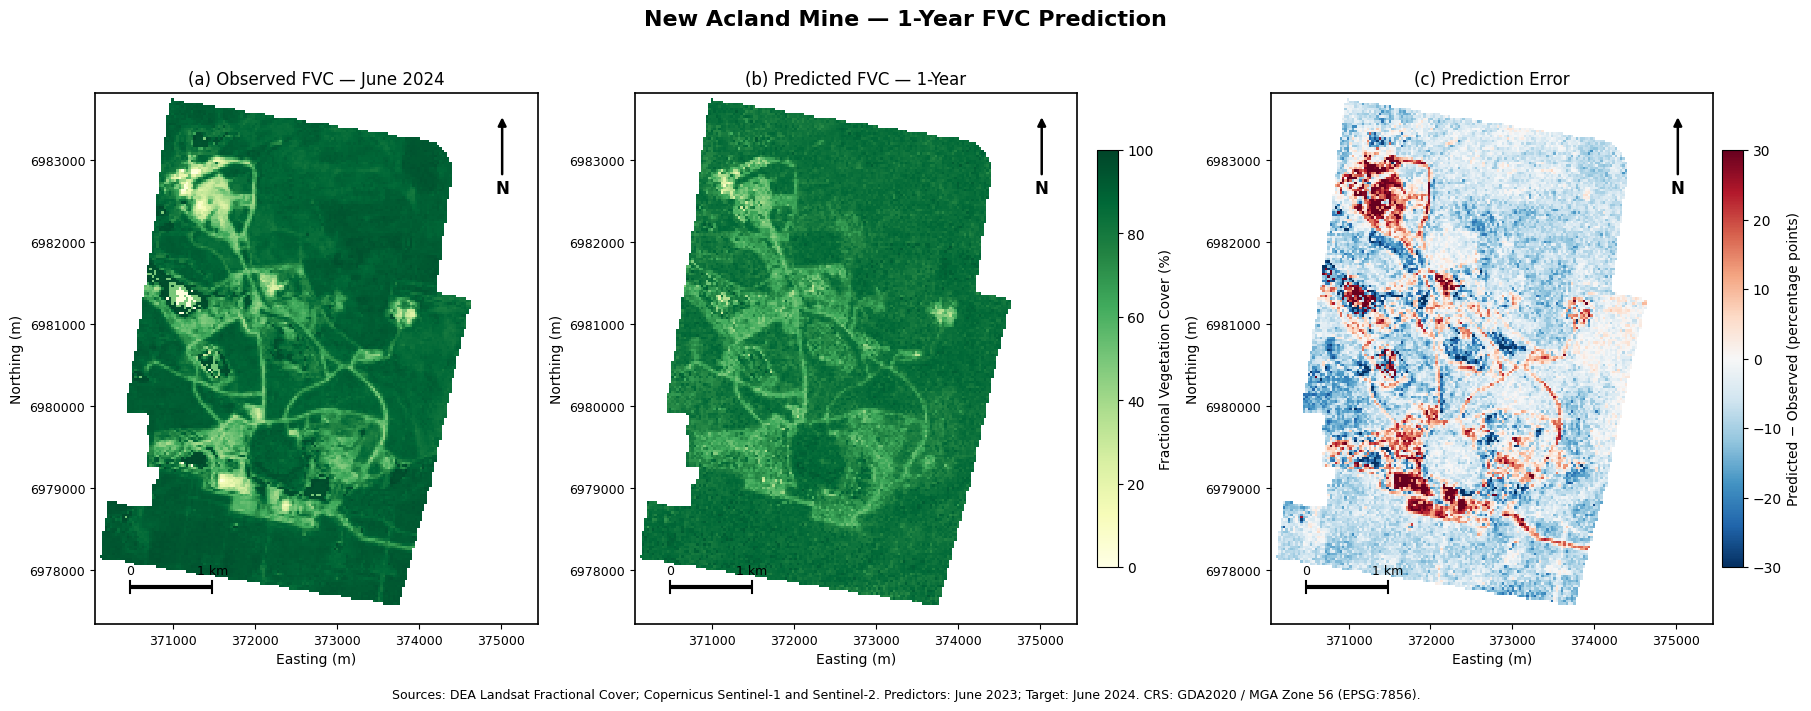

Saved: Report_Figures/Report_1Year_FVC_Prediction.png
Mean prediction error: -4.14


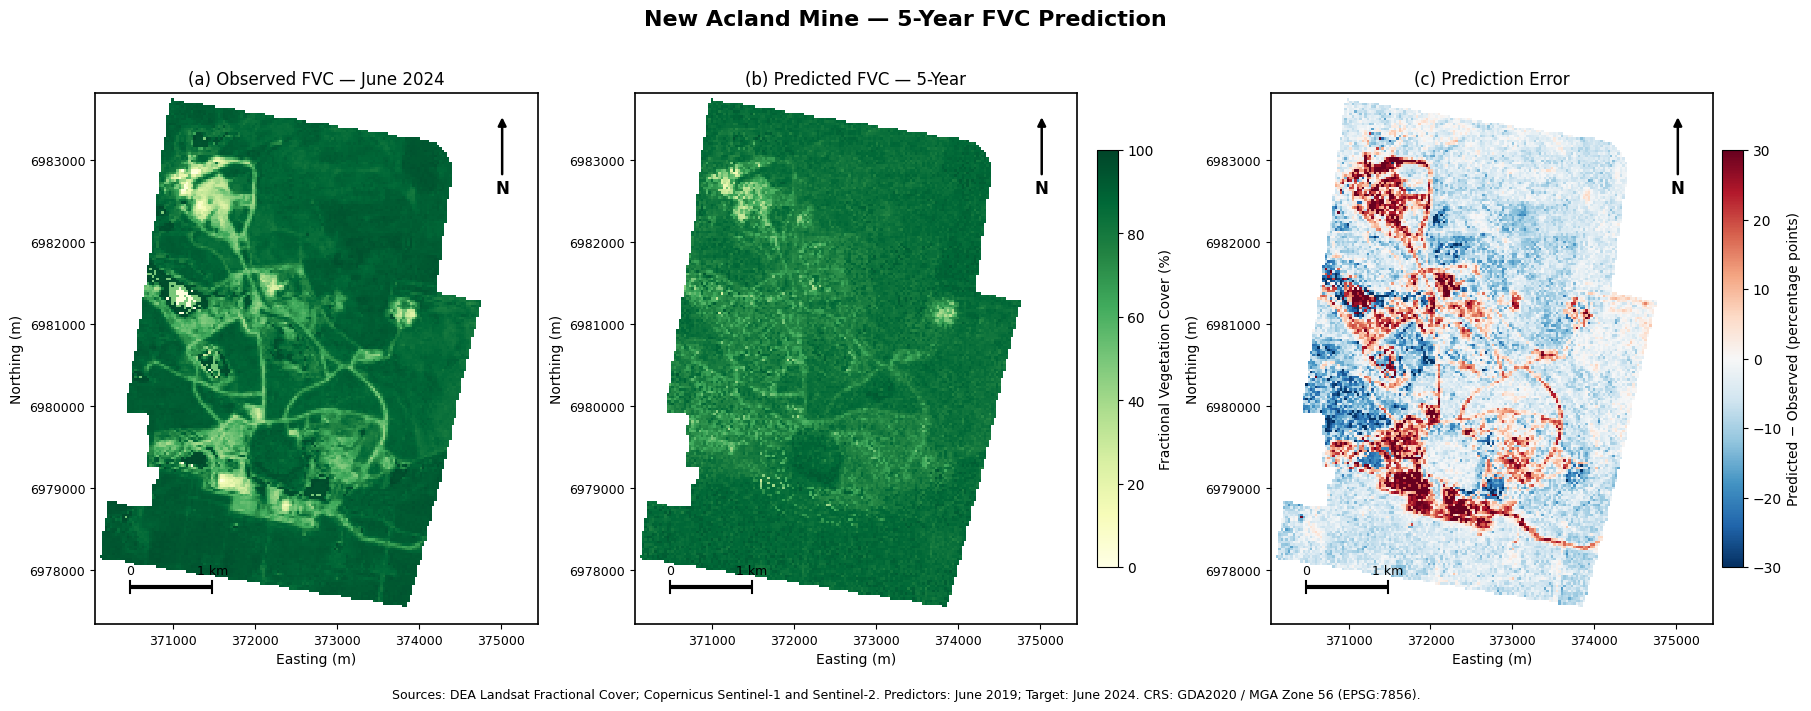

Saved: Report_Figures/Report_5Year_FVC_Prediction.png
Mean prediction error: -2.22


In [17]:
plot_report_prediction(
    predicted=pred_1yr_full,
    observed=observed_full,
    horizon="1-Year",
    predictor_year=2023,
)

plot_report_prediction(
    predicted=pred_5yr_full,
    observed=observed_full,
    horizon="5-Year",
    predictor_year=2019,
)